# Blind separation of BPSK, QPSK, 8PSK, π/4-DQPSK and MSK with the zero-lag cyclic autocorrelation

**A hands-on tutorial of the theorem, its assumptions, every lemma, and every proof.**

The companion write-up (`caf_separability.tex`) proves that the zero-lag, all-unconjugated cyclic autocorrelations (CAFs) of orders 2, 4 and 8 separate the five classes without knowing the carrier offset, phase, timing, symbol rate, amplitude or (within limits) the pulse. This notebook walks through the same argument, in the same order, and checks every step numerically.

**One toy example is used throughout:**

| Quantity | Value |
|---|---|
| Samples per symbol $T$ | 16 (MSK: $T_b = 8$) |
| Pulse | root-raised-cosine, roll-off $\beta = 0.35$ (MSK: half-sine) |
| Record length | $N = 2^{18}$ samples (16 384 symbols) |
| Carrier offset $f_0$ | $5/1024 \approx 0.0049$ cycles/sample |
| SNR | 15 dB, circular complex Gaussian noise |
| $A,\ \varphi,\ t_0$ | drawn at random, unknown to the receiver |

Frequencies are in cycles/sample and times in samples, so $T = 16$ means "16 samples". The notebook is in discrete time, while the proof is in continuous time; where that matters (twice) it is pointed out.

**Contents**

1. Signal model
2. Assumptions A1–A6
3. Definitions: the zero-lag CAF and the "type"
4. Lemmas 0–9, each stated, proved in words, and verified
5. Theorems 1–3
6. Plain DQPSK (why it is excluded)
7. Remarks: when the assumptions fail

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (10, 3.4), "axes.grid": True, "grid.alpha": 0.3})

# ----- toy-example parameters (used everywhere) -----
SPS    = 16            # T, samples per symbol  (MSK: T_b = SPS // 2)
BETA   = 0.35          # RRC roll-off
SPAN   = 8             # RRC half-length, in symbols
NSAMP  = 2**18         # record length
F0     = 5 / 1024      # carrier offset, on the FFT grid for every N >= 1024
SNR_DB = 15.0
KAPPA  = 6.0           # line-detection threshold, in noise-floor standard deviations

CLASSES = ["BPSK", "QPSK", "8PSK", "pi/4-DQPSK", "MSK"]

def wrap(f):
    # map a frequency to [-0.5, 0.5)
    return (np.asarray(f) + 0.5) % 1.0 - 0.5

## 1. Signal model

The observation is $y = s + w$. The linear classes are

$$s(t) = A\,e^{j(2\pi f_0 t+\varphi)}\sum_k a_k\,p(t-kT-t_0),$$

and MSK is written in its OQPSK form, with two ±1 rails offset by $T_b$ and a half-sine pulse $q$:

$$s(t) = A\,e^{j(2\pi f_0 t+\varphi)}\Big[\sum_k a_k\,q(t-2kT_b-t_0) + j\sum_k b_k\,q(t-(2k+1)T_b-t_0)\Big].$$

The next cell implements the pulses, the symbol sources, and a generator `make_signal` that draws $A$, $\varphi$ and $t_0$ at random.

In [2]:
# ---------------- pulses (all real, as required by A3) ----------------
def rrc(beta=BETA, sps=SPS, span=SPAN):
    t = np.arange(-span * sps, span * sps + 1) / sps
    p = np.empty_like(t)
    for i, ti in enumerate(t):
        if np.isclose(ti, 0.0):
            p[i] = 1 - beta + 4 * beta / np.pi
        elif np.isclose(abs(4 * beta * ti), 1.0):
            p[i] = beta / np.sqrt(2) * ((1 + 2/np.pi) * np.sin(np.pi / (4*beta))
                                        + (1 - 2/np.pi) * np.cos(np.pi / (4*beta)))
        else:
            p[i] = (np.sin(np.pi*ti*(1-beta)) + 4*beta*ti*np.cos(np.pi*ti*(1+beta))) \
                   / (np.pi * ti * (1 - (4*beta*ti)**2))
    return p / np.sqrt(np.sum(p**2) / sps)       # unit average output power

def rect(sps=SPS):
    return np.ones(sps)

def half_sine(tb=SPS // 2):
    t = np.arange(-tb, tb)                        # support |t| < T_b
    return np.cos(np.pi * t / (2 * tb))

# ---------------- symbol sources (A2) ----------------
def psk_symbols(M, K):
    theta_c = 0.0 if M == 2 else np.pi / M        # QPSK: pi/4 offset, 8PSK: pi/8 offset
    return np.exp(1j * (theta_c + 2 * np.pi * rng.integers(0, M, K) / M))

def pi4_dqpsk_symbols(K):
    d = rng.choice(np.array([1, 3, -1, -3]) * np.pi / 4, K)   # increments in D
    return np.exp(1j * np.cumsum(d))

def dqpsk_symbols(K):                              # plain DQPSK (Section 6)
    return np.exp(1j * np.cumsum(rng.integers(0, 4, K) * np.pi / 2))

def symbols_for(cls, K):
    return {"BPSK": lambda: psk_symbols(2, K), "QPSK": lambda: psk_symbols(4, K),
            "8PSK": lambda: psk_symbols(8, K), "pi/4-DQPSK": lambda: pi4_dqpsk_symbols(K),
            "DQPSK": lambda: dqpsk_symbols(K)}[cls]()

# ---------------- waveforms ----------------
def pam(symbols, p, sps=SPS):
    up = np.zeros(len(symbols) * sps, dtype=complex)
    up[::sps] = symbols
    return np.convolve(up, p)[: len(up)]

def msk_baseband(K, tb=SPS // 2):
    q, n = half_sine(tb), 2 * tb * K
    ui = np.zeros(n); ui[::2 * tb] = rng.choice([-1.0, 1.0], K)    # I rail, a_k
    uq = np.zeros(n); uq[tb::2 * tb] = rng.choice([-1.0, 1.0], K)  # Q rail, b_k, offset T_b
    return np.convolve(ui, q)[:n] + 1j * np.convolve(uq, q)[:n]

def baseband(cls, nsamp=NSAMP, sps=SPS, pulse=None):
    K = nsamp // sps
    if cls == "MSK":   return msk_baseband(K, sps // 2)
    if cls == "noise": return np.zeros(nsamp, complex)
    return pam(symbols_for(cls, K), rrc(sps=sps) if pulse is None else pulse, sps)

def make_signal(cls, nsamp=NSAMP, sps=SPS, pulse=None, f0=F0, A=None, phi=None, t0=None,
                snr_db=SNR_DB, channel=None, noise="circular"):
    # returns y and the (hidden) true parameters
    A   = rng.uniform(0.5, 2.0)        if A   is None else A
    phi = rng.uniform(0, 2 * np.pi)    if phi is None else phi
    t0  = int(rng.integers(0, sps))    if t0  is None else t0
    x = np.roll(baseband(cls, nsamp, sps, pulse), t0)
    if channel is not None:
        x = np.convolve(x, channel)[:nsamp]
    k = np.arange(nsamp)
    s = A * np.exp(1j * (2 * np.pi * f0 * k + phi)) * x
    info = dict(cls=cls, A=A, phi=phi, t0=t0, f0=f0)
    if snr_db is None:
        return s, info
    ps = np.mean(np.abs(s)**2) if cls != "noise" else 1.0
    var = ps / 10**(snr_db / 10)
    if noise == "circular":
        w = np.sqrt(var / 2) * (rng.standard_normal(nsamp) + 1j * rng.standard_normal(nsamp))
    else:                                           # "real": NON-circular noise, violates A5
        w = np.sqrt(var) * rng.standard_normal(nsamp)
    return s + w, info

### What the five classes look like

Symbol constellations first. π/4-DQPSK is coloured by symbol parity, which shows it alternating between two QPSK constellations rotated by π/4 — the property that will produce its offset fourth-order lines. MSK is shown as its I/Q waveforms: its envelope is exactly constant.

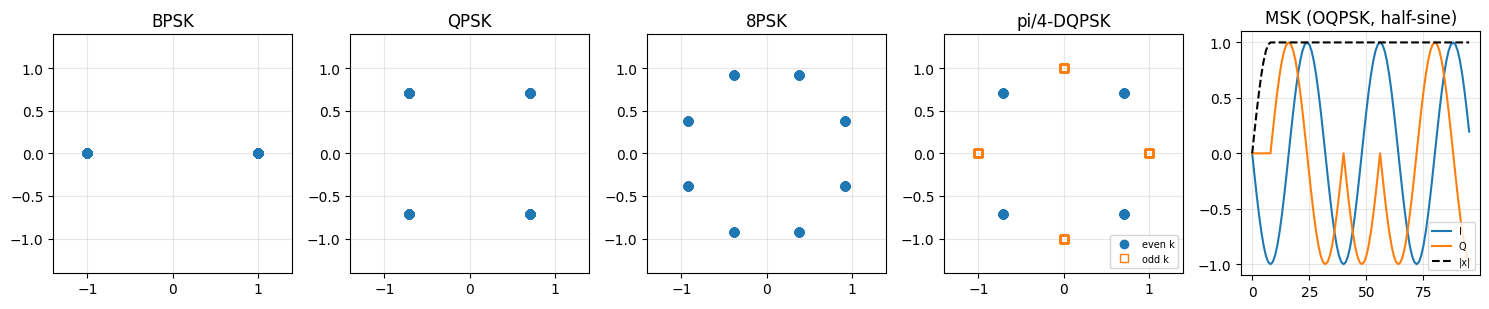

In [3]:
fig, axs = plt.subplots(1, 5, figsize=(15, 3.2))
K = 400
for ax, cls in zip(axs[:4], ["BPSK", "QPSK", "8PSK", "pi/4-DQPSK"]):
    a = symbols_for(cls, K)
    if cls == "pi/4-DQPSK":
        ax.plot(a[::2].real, a[::2].imag, "o", label="even k")
        ax.plot(a[1::2].real, a[1::2].imag, "s", mfc="none", label="odd k")
        ax.legend(fontsize=7, loc="lower right")
    else:
        ax.plot(a.real, a.imag, "o")
    ax.set_title(cls); ax.set_aspect("equal"); ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)

x = msk_baseband(6)
axs[4].plot(x.real, label="I"); axs[4].plot(x.imag, label="Q")
axs[4].plot(np.abs(x), "k--", label="|x|")
axs[4].set_title("MSK (OQPSK, half-sine)"); axs[4].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 2. Assumptions

| | Assumption | Where it is used |
|---|---|---|
| **A1** | $A, f_0, \varphi, t_0, T, T_b$ are unknown **constants** (static flat channel, stable carrier and clock) | lines stay sharp |
| **A2** | Symbols: i.i.d. uniform M-PSK; π/4-DQPSK with i.i.d. increments in $\{\pm\pi/4,\pm3\pi/4\}$; MSK with i.i.d. ±1 rails | Lemmas 1–4 |
| **A3** | $p, q$ real, bounded, not a.e. zero, with $S_p = \sup_t\sum_k \lvert p(t-kT)\rvert < \infty$ | symmetry, positive center |
| **A4** | Non-degeneracy: $G_4\big(\tfrac{2m+1}{2T}\big)\ne 0$ for some $m$ (π/4-DQPSK); $Q_2\big(\tfrac{2m+1}{2T_b}\big)\ne 0$ for some $m$ (MSK) | offset lines exist |
| **A5** | Noise independent of $s$ with **all unconjugated moments zero** (circular) | Lemma 5 |
| **A6** | Exactly one signal from the closed set is present | Theorem 1 |

Here $G_n = \widehat{p^n}$ and $Q_2 = \widehat{q^2}$ are Fourier transforms. The next cells check A3, A4 and A5 for the toy example, and show what goes wrong when they fail.

In [4]:
def dtft(f, nu):
    # Fourier transform of a sampled real pulse at frequencies nu (cycles/sample)
    t = np.arange(len(f))
    return np.exp(-2j * np.pi * np.outer(np.atleast_1d(nu), t)) @ f

def periodic_sum(f, P, N, alternating=False):
    # F(t) = sum_k (+-1)^k f(t - kP), built exactly by circular convolution over N samples
    comb = np.zeros(N)
    comb[::P] = (-1.0) ** np.arange(N // P) if alternating else 1.0
    return np.fft.ifft(np.fft.fft(comb) * np.fft.fft(f, N))

p = rrc()
# ---- A3: real pulses with finite S_p ----
for name, f in [("RRC", p), ("rect", rect()), ("half-sine (P = T_b)", half_sine())]:
    P = SPS // 2 if "half" in name else SPS
    S = np.max(np.abs(periodic_sum(np.abs(f), P, 64 * SPS)))
    print(f"A3  {name:20s}: real = {np.isrealobj(f)},  S_p = {S:.3f} < inf")

# ---- A4: non-degeneracy ----
T = SPS
print()
for name, f in [("RRC", p), ("rect", rect()), ("box of width 2T (counterexample)", np.ones(2 * T))]:
    g = np.abs(dtft(f**4, (2 * np.arange(-3, 3) + 1) / (2 * T)))
    print(f"A4  {name:34s}: max_m |G4((2m+1)/2T)| = {g.max():8.4f}")
Q2 = np.abs(dtft(half_sine()**2, 1 / (2 * (SPS // 2))))
print(f"A4  {'MSK half-sine':34s}: |Q2(1/2T_b)| = {Q2[0]:.4f}  (= T_b/2 = {SPS//4})")

A3  RRC                 : real = True,  S_p = 1.600 < inf
A3  rect                : real = True,  S_p = 1.000 < inf
A3  half-sine (P = T_b) : real = True,  S_p = 1.414 < inf

A4  RRC                               : max_m |G4((2m+1)/2T)| =  10.4943
A4  rect                              : max_m |G4((2m+1)/2T)| =  10.2023
A4  box of width 2T (counterexample)  : max_m |G4((2m+1)/2T)| =   0.0000
A4  MSK half-sine                     : |Q2(1/2T_b)| = 4.0000  (= T_b/2 = 4)


The width-$2T$ box is a genuine counterexample to A4: its alternating sum $\sum_k(-1)^k p^4(t-kT)$ is identically zero, because each point is covered by exactly two consecutive pulses with opposite signs. A π/4-DQPSK signal with that pulse would have **no** fourth-order lines at all.

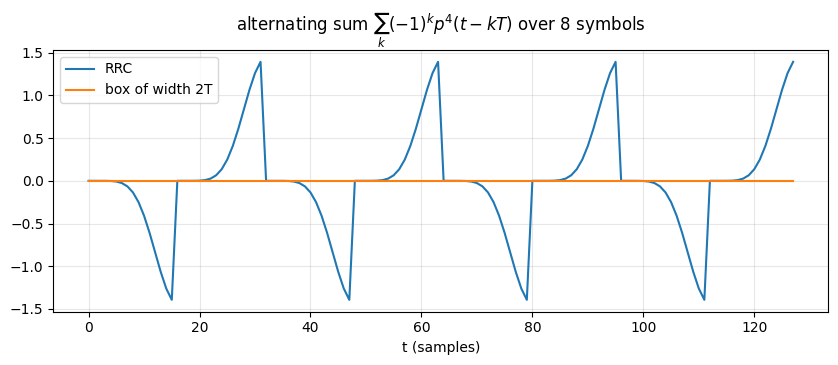

In [5]:
fig, ax = plt.subplots()
for name, f in [("RRC", p), ("box of width 2T", np.ones(2 * T))]:
    h = periodic_sum(f**4, T, 8 * T, alternating=True).real
    ax.plot(h, label=name)
ax.set_title(r"alternating sum $\sum_k(-1)^k p^4(t-kT)$ over 8 symbols"); ax.set_xlabel("t (samples)")
ax.legend(); plt.show()

In [6]:
# ---- A5: circular vs non-circular noise, unconjugated moments E[w^m] ----
n = 10**6
w_circ = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) / np.sqrt(2)
w_real = rng.standard_normal(n)
print(" m   |E[w^m]| circular    |E[w^m]| real (non-circular)")
for m in range(1, 9):
    print(f"{m:2d}      {abs(np.mean(w_circ**m)):10.4f}          {abs(np.mean(w_real**m)):10.4f}")

 m   |E[w^m]| circular    |E[w^m]| real (non-circular)
 1          0.0003              0.0008
 2          0.0024              0.9999
 3          0.0025              0.0021
 4          0.0021              3.0011
 5          0.0109              0.0243
 6          0.0466             15.0016
 7          0.0427              0.3385
 8          0.0466            104.7561


Circular noise has every unconjugated moment ≈ 0 (the residuals are Monte Carlo error), so it cannot create lines in $y^n$. Real (non-circular) noise has $E[w^2]=\sigma^2$, $E[w^4]=3\sigma^4$, … — it violates A5, and Section 4 (Lemma 5) shows the damage.

## 3. Definitions

**Definition 1 (zero-lag CAF).** With $m_n(t) = E[y^n(t)]$,

$$R_n^\alpha = \lim_{L\to\infty}\frac{1}{2L}\int_{-L}^{L} m_n(t)\,e^{-j2\pi\alpha t}\,dt,\qquad M_n(\alpha) = \lvert R_n^\alpha\rvert.$$

In practice we use the time-average estimate $\hat R_n^\alpha = \frac1N\sum_k y^n[k]e^{-j2\pi\alpha k}$, i.e. **the FFT of $y^n$ divided by $N$**. Lines are then detected against a local noise floor.

**Definition 2 (type).** $\tau_n = \varnothing$ if $M_n\equiv 0$. Otherwise let $c_n$ be the unique symmetry center of $M_n$; $\tau_n = \mathrm{C}$ ("centered") if $M_n(c_n)>0$ and $\tau_n = \mathrm{O}$ ("offset") if $M_n(c_n)=0$.

For data we compute the type with the **peak-symmetry test** of Theorem 2 (strongest line; is the line pattern symmetric about it?). Section 4, Lemma 8, explains why this is also the right choice in discrete time.

In [7]:
def caf(y, n):
    # zero-lag, all-unconjugated CAF estimate: FFT of y^n / N, on alpha in [-0.5, 0.5)
    z = y**n
    R = np.fft.fftshift(np.fft.fft(z)) / len(z)
    alpha = np.fft.fftshift(np.fft.fftfreq(len(z)))
    return alpha, R

def detect_lines(alpha, R, kappa=KAPPA):
    # keep bins exceeding kappa * local noise-floor std (block median of a Rayleigh floor)
    a = np.abs(R)
    block = min(1024, len(a) // 8)
    nb = len(a) // block
    med = np.median(a[: nb * block].reshape(nb, block), axis=1)
    floor = np.repeat(med, block)
    floor = np.concatenate([floor, np.full(len(a) - len(floor), med[-1])]) / np.sqrt(np.log(2))
    idx = np.flatnonzero(a > kappa * floor)
    return alpha[idx], a[idx]

def line_type(al, mag, df, strong=0.25, rtol=0.3):
    # peak-symmetry test (Theorem 2): returns (type, strongest-line location)
    if len(al) == 0:
        return "∅", None
    i = int(np.argmax(mag)); a_star = al[i]
    for a, m in zip(al, mag):
        if m < strong * mag[i]:
            continue
        mirror = wrap(2 * a_star - a)
        j = int(np.argmin(np.abs(wrap(al - mirror))))
        if abs(wrap(al[j] - mirror)) > 1.5 * df or abs(mag[j] - m) > rtol * m:
            return "O", a_star
    return "C", a_star

def types_of(y, orders=(2, 4, 8)):
    out = {}
    for n in orders:
        alpha, R = caf(y, n)
        al, mag = detect_lines(alpha, R)
        out[n] = line_type(al, mag, alpha[1] - alpha[0])[0]
    return out

def classify(y):
    t = types_of(y)
    if t[2] == "C": c = "BPSK"
    elif t[2] == "O": c = "MSK"
    elif t[4] == "C": c = "QPSK"
    elif t[4] == "O": c = "pi/4-DQPSK"
    elif t[8] == "C": c = "8PSK"
    else: c = "noise"
    return c, t

### Theoretical lines (Lemma 6), used for every overlay below

The next helper evaluates the closed-form line magnitudes that Lemma 6 predicts. Every plot in the notebook overlays these (circles) on the measured CAF (line).

In [8]:
def theory_lines(cls, n, A=1.0, sps=SPS, pulse=None, f0=F0):
    # Lemma 6. Returns (alpha, M) or None when the lemma does not tabulate that (class, n).
    T = sps
    pulse = rrc(sps=sps) if pulse is None else pulse
    order = {"BPSK": 2, "QPSK": 4, "8PSK": 8, "DQPSK": 4}
    if cls == "noise":
        return np.array([]), np.array([])
    if cls in order:
        M = order[cls]
        if n < M: return np.array([]), np.array([])
        if n > M: return None
        nu = np.arange(-(T // 2) + 1, T // 2) / T              # integer lattice k/T
        mag = A**n * np.abs(dtft(pulse**n, nu)) / T
    elif cls == "pi/4-DQPSK":
        if n == 2: return np.array([]), np.array([])
        if n != 4: return None
        nu = (np.arange(-(T // 2), T // 2) + 0.5) / T          # half lattice (m + 1/2)/T
        mag = A**4 * np.abs(dtft(pulse**4, nu)) / T
    elif cls == "MSK":
        if n != 2: return None
        Tb = sps // 2
        nu = (np.arange(-(Tb // 2), Tb // 2) + 0.5) / Tb       # half lattice (m + 1/2)/T_b
        mag = A**2 * np.abs(dtft(half_sine(Tb)**2, nu)) / Tb
    keep = mag > 1e-3 * mag.max()
    return wrap(n * f0 + nu[keep]), mag[keep]

def plot_caf(ax, y, n, info=None, span=3.0, sps=SPS, pulse=None, title=None):
    alpha, R = caf(y, n)
    f0 = F0 if info is None else info["f0"]
    x = wrap(alpha - n * f0) * sps                 # offset from n f0, in units of 1/T
    sel = np.abs(x) <= span
    ax.plot(x[sel], np.abs(R[sel]), lw=0.8, label=r"$|\hat R_n^\alpha|$")
    if info is not None:
        th = theory_lines(info["cls"], n, A=info["A"], sps=sps, pulse=pulse, f0=f0)
        if th is not None and len(th[0]):
            xt = wrap(th[0] - n * f0) * sps
            m = np.abs(xt) <= span
            ax.plot(xt[m], th[1][m], "o", mfc="none", ms=8, label="Lemma 6")
    ax.set_xlabel(r"$(\alpha - n f_0)\,T$")
    ax.set_title(title or f"n = {n}")
    ax.legend(fontsize=7)

## 4. Lemmas

### Lemma 0 — Fourier coefficients of periodic sums

**Statement.** For $f\in L^1$, the periodic sum $F(t)=\sum_k f(t-kP-t_0)$ has time-average Fourier coefficient $\frac1P\hat f(\alpha)e^{-j2\pi\alpha t_0}$ on the lattice $\alpha\in\frac1P\mathbb{Z}$ and zero elsewhere. The **alternating** sum $\sum_k(-1)^kf(t-kP-t_0)$ has the same coefficients but on the **half lattice** $\alpha\in\frac1P(\mathbb{Z}+\tfrac12)$. A finite-energy transient contributes nothing.

**Proof idea.** Average over whole periods (the remainder is $O(1/L)$), then "unfold" the periodic sum into a single integral of $f$. For the alternating sum, split into even and odd $k$; the two halves add with a factor $1-e^{-j2\pi\alpha P}$, which is $0$ on integer multiples of $1/P$ and $2$ on odd half-multiples.

**Check.** Take $f=p^4$ (the RRC pulse to the 4th power) and $P = T$.

periodic   : max |measured - predicted| = 7.26e-15
alternating: max |measured - predicted| = 6.33e-15


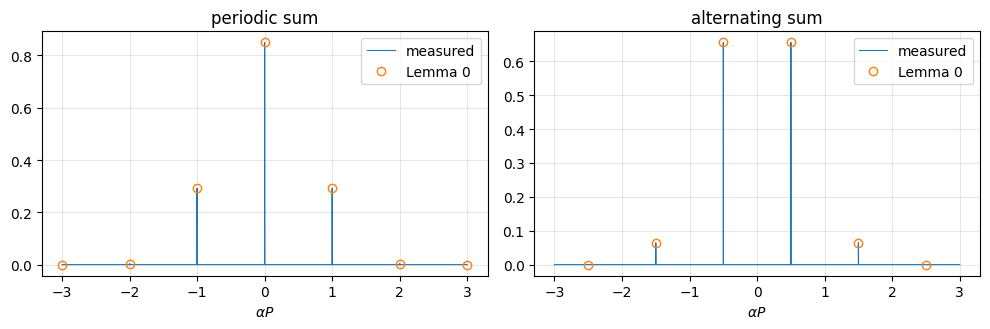

In [9]:
N0, P = 2**14, SPS
f = rrc()**4
alpha = np.fft.fftfreq(N0)
pred_all = dtft(f, alpha) / P
fig, axs = plt.subplots(1, 2)
for ax, alt in zip(axs, (False, True)):
    F = periodic_sum(f, P, N0, alternating=alt)
    C = np.fft.fft(F) / N0                                    # time-average coefficients
    x = (2 if alt else 1) * alpha * P
    on = np.isclose(x, np.round(x)) & ((np.round(x) % 2 == 1) if alt else True)
    pred = np.where(on, pred_all, 0)
    print(f"{'alternating' if alt else 'periodic   '}: max |measured - predicted| = {np.max(np.abs(C - pred)):.2e}")
    s = np.argsort(alpha); a = alpha[s] * P
    m = np.abs(a) <= 3
    ax.plot(a[m], np.abs(C[s][m]), lw=0.8, label="measured")
    ax.plot(a[m][on[s][m]], np.abs(pred[s][m][on[s][m]]), "o", mfc="none", label="Lemma 0")
    ax.set_title("alternating sum" if alt else "periodic sum"); ax.set_xlabel(r"$\alpha P$"); ax.legend()
plt.tight_layout(); plt.show()

The periodic sum has lines at integers (in units of $1/P$), including 0. The alternating sum has lines only at odd half-integers, and **nothing at 0**. Everything that follows is this picture, applied to different $f$.

### Lemma 1 — M-PSK moments

**Statement.** $E[a^r] = e^{jr\theta_c}\,\mathbb{1}[M\mid r]$.

**Proof.** $E[a^r]$ is $e^{jr\theta_c}$ times the average of the $M$-th roots of unity raised to the power $r$, a geometric sum equal to 1 when $M$ divides $r$ and 0 otherwise.

In [10]:
print("  r :" + "".join(f"{r:7d}" for r in range(1, 9)))
for M in (2, 4, 8):
    a = psk_symbols(M, 200_000)
    emp = [abs(np.mean(a**r)) for r in range(1, 9)]
    th  = [1.0 if r % M == 0 else 0.0 for r in range(1, 9)]
    print(f"{M}PSK measured |E[a^r]|:" + "".join(f"{v:7.3f}" for v in emp))
    print(f"{M}PSK Lemma 1         :" + "".join(f"{v:7.0f}" for v in th))

  r :      1      2      3      4      5      6      7      8
2PSK measured |E[a^r]|:  0.001  1.000  0.001  1.000  0.001  1.000  0.001  1.000
2PSK Lemma 1         :      0      1      0      1      0      1      0      1
4PSK measured |E[a^r]|:  0.002  0.000  0.002  1.000  0.002  0.000  0.002  1.000
4PSK Lemma 1         :      0      0      0      1      0      0      0      1
8PSK measured |E[a^r]|:  0.001  0.002  0.001  0.001  0.001  0.002  0.001  1.000
8PSK Lemma 1         :      0      0      0      0      0      0      0      1


So BPSK has its first nonzero moment at $r=2$, QPSK at $r=4$, 8PSK at $r=8$. That is exactly why the classifier looks at orders 2, 4, 8.

### Lemma 2 — products of i.i.d. symbols

**Statement.** If $E[a^r]=0$ for $1\le r<n$, then $E[a_{k_1}\cdots a_{k_n}] = E[a^n]\cdot\mathbb 1[k_1=\cdots=k_n]$; if also $E[a^n]=0$, every product has zero mean.

**Proof.** Group equal indices into blocks; independence factors the expectation into $\prod_b E[a^{r_b}]$. Any partition with two or more blocks has a block with $r_b<n$, whose factor is 0.

**Check** with QPSK and $n=4$:

In [11]:
a = psk_symbols(4, 4 * 500_000).reshape(-1, 4)       # columns = four independent symbol indices
patterns = {"(0,0,0,0)": [0, 0, 0, 0], "(0,0,1,1)": [0, 0, 1, 1], "(0,0,0,1)": [0, 0, 0, 1],
            "(0,0,1,2)": [0, 0, 1, 2], "(0,1,2,3)": [0, 1, 2, 3]}
for name, idx in patterns.items():
    v = np.mean(np.prod(a[:, idx], axis=1))
    th = -1.0 if len(set(idx)) == 1 else 0.0          # E[a^4] = e^{j*4*pi/4} = -1
    print(f"E[a_k1 a_k2 a_k3 a_k4], indices {name}: measured {v.real:+.3f}{v.imag:+.3f}j   Lemma 2: {th:+.0f}")

E[a_k1 a_k2 a_k3 a_k4], indices (0,0,0,0): measured -1.000+0.000j   Lemma 2: -1
E[a_k1 a_k2 a_k3 a_k4], indices (0,0,1,1): measured -0.003+0.000j   Lemma 2: +0
E[a_k1 a_k2 a_k3 a_k4], indices (0,0,0,1): measured +0.001-0.001j   Lemma 2: +0
E[a_k1 a_k2 a_k3 a_k4], indices (0,0,1,2): measured +0.000+0.002j   Lemma 2: +0
E[a_k1 a_k2 a_k3 a_k4], indices (0,1,2,3): measured -0.000-0.000j   Lemma 2: +0


### Lemma 3 — products of π/4-DQPSK symbols

**Statement.** For $n\in\{2,4\}$, $E[a_{k_1}\cdots a_{k_n}]$ is zero unless all indices equal some $k$; then it is $\mathbb 1[k=0]$ for $n=2$ and $(-1)^k$ for $n=4$.

**Proof.** Write the phase sum as $\sum_\ell\psi_{k_\ell} = \sum_i c_i\Delta_i$, where the integer $c_i$ counts how many of the indices lie "beyond" increment $i$. The increments are independent, so the expectation is $\prod_i E[e^{jc_i\Delta}]$, and

$$E[e^{jc\Delta}] = \tfrac12\Big[\cos\tfrac{c\pi}4 + \cos\tfrac{3c\pi}4\Big] = 0 \text{ for } |c|\in\{1,2,3\},\qquad -1 \text{ for } |c| = 4.$$

If the indices differ, the increment just after the largest-but-one index has $1\le|c_i|\le3$, which kills the product.

In [12]:
D = np.array([1, 3, -1, -3]) * np.pi / 4
print("c:", "  ".join(f"{c:+d}->{np.mean(np.exp(1j*c*D)).real:+.0f}" for c in range(-4, 5)))

def increment_coeffs(idx):
    # c_i: for i >= 1, #{k_l >= i};  for i <= 0, -#{k_l < i}
    idx = np.asarray(idx)
    out = {}
    for i in range(min(idx.min(), 0), max(idx.max(), 0) + 2):
        c = np.sum(idx >= i) if i >= 1 else -np.sum(idx < i)
        if c: out[i] = int(c)
    return out

def pi4_phases(kmin, kmax, ndraw):
    # psi_0 = 0; forward for k > 0, backward for k < 0 (A2(b))
    d = {i: rng.choice(D, ndraw) for i in range(kmin + 1, kmax + 1)}
    psi = {0: np.zeros(ndraw)}
    for k in range(1, kmax + 1):  psi[k] = psi[k - 1] + d[k]
    for k in range(-1, kmin - 1, -1): psi[k] = psi[k + 1] - d[k + 1]
    return psi

psi = pi4_phases(-4, 4, 400_000)
tests = [(0, 0), (1, 1), (0, 1), (2, 2, 2, 2), (3, 3, 3, 3), (-3, -3, -3, -3), (0, 0, 1, 1), (0, 1, 1, 1), (-1, 0, 0, 1)]
print(f"\n{'indices':18s} {'coefficients c_i':28s} {'measured':>10s} {'Lemma 3':>8s}")
for idx in tests:
    v = np.mean(np.exp(1j * sum(psi[k] for k in idx)))
    n, same = len(idx), len(set(idx)) == 1
    th = (1.0 if idx[0] == 0 else 0.0) if (n == 2 and same) else ((-1.0)**idx[0] if same else 0.0)
    print(f"{str(idx):18s} {str(increment_coeffs(idx)):28s} {v.real:+10.3f} {th:+8.0f}")

a = pi4_dqpsk_symbols(20)
print("\na_k^4 * (-1)^k for k = 0..19 (a deterministic constant):", np.round(a**4 * (-1.0)**np.arange(20), 6)[:6], "...")

c: -4->-1  -3->+0  -2->-0  -1->+0  +0->+1  +1->+0  +2->-0  +3->+0  +4->-1

indices            coefficients c_i               measured  Lemma 3
(0, 0)             {}                               +1.000       +1
(1, 1)             {1: 2}                           -0.000       +0
(0, 1)             {1: 1}                           +0.002       +0
(2, 2, 2, 2)       {1: 4, 2: 4}                     +1.000       +1
(3, 3, 3, 3)       {1: 4, 2: 4, 3: 4}               -1.000       -1
(-3, -3, -3, -3)   {-2: -4, -1: -4, 0: -4}          -1.000       -1
(0, 0, 1, 1)       {1: 2}                           -0.000       +0
(0, 1, 1, 1)       {1: 3}                           -0.002       +0
(-1, 0, 0, 1)      {0: -1, 1: 1}                    +0.001       +0

a_k^4 * (-1)^k for k = 0..19 (a deterministic constant): [-1.+0.j -1.+0.j -1.+0.j -1.+0.j -1.+0.j -1.+0.j] ...


The last line is the key physical fact: $a_k^4$ is not random at all. It is a deterministic sequence that flips sign every symbol, so its "spectral line" sits half a symbol rate away from the center.

### Lemma 4 — moments of the signal

**Statement.**

| Class | Moment |
|---|---|
| BPSK | $E[s^2] = A^2e^{j2\theta}e^{j4\pi f_0t}\sum_k p^2(t-kT-t_0)$ |
| QPSK | $E[s^2]=0$, $\;E[s^4] = A^4e^{j4\theta}e^{j8\pi f_0t}\sum_k p^4(t-kT-t_0)$ |
| 8PSK | $E[s^2]=E[s^4]=0$, $\;E[s^8] = A^8e^{j8\theta}e^{j16\pi f_0t}\sum_k p^8(t-kT-t_0)$ |
| π/4-DQPSK | $E[s^2]=0$ (up to a transient), $\;E[s^4] = A^4e^{j4\theta}e^{j8\pi f_0t}\sum_k (-1)^k p^4(t-kT-t_0)$ |
| MSK | $E[s^2] = A^2e^{j2\theta}e^{j4\pi f_0t}\sum_k (-1)^k q^2(t-kT_b-t_0)$ |

**Proof.** Expand $s^n$, exchange sum and expectation (justified by A3), and apply Lemma 2 (M-PSK) or Lemma 3 (π/4-DQPSK). For MSK, $(I+jQ)^2 = I^2 - Q^2 + 2jIQ$; the cross term has zero mean, and $I^2$, $Q^2$ are sums of $q^2$ on the even and odd multiples of $T_b$.

**Check.** Average $s^n(t)$ over 4000 independent realizations (with $A=1$, $\varphi=0$, $f_0=0$) and compare with the formulas.

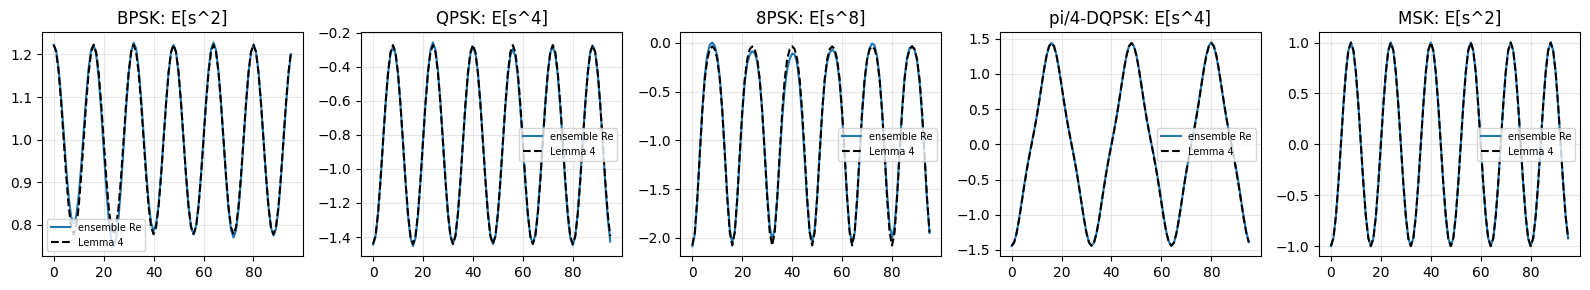

QPSK       max |E[s^2]| = 0.036   (Lemma 4: 0; the residual is Monte Carlo noise, shrinking like 1/sqrt(R), R = 4000)
8PSK       max |E[s^2]| = 0.046   (Lemma 4: 0; the residual is Monte Carlo noise, shrinking like 1/sqrt(R), R = 4000)
8PSK       max |E[s^4]| = 0.047   (Lemma 4: 0; the residual is Monte Carlo noise, shrinking like 1/sqrt(R), R = 4000)
pi/4-DQPSK max |E[s^2]| = 0.027   (Lemma 4: 0; the residual is Monte Carlo noise, shrinking like 1/sqrt(R), R = 4000)


In [13]:
def fftconv_rows(U, h):
    n = U.shape[1]; L = n + len(h) - 1; nfft = 1 << (L - 1).bit_length()
    return np.fft.ifft(np.fft.fft(U, nfft, axis=1) * np.fft.fft(h, nfft), axis=1)[:, :n]

R_ENS, K_ENS = 4000, 48
p = rrc(); Tb = SPS // 2; q = half_sine(Tb); nlen = K_ENS * SPS

def ensemble(cls, n):
    if cls == "MSK":
        ui = np.zeros((R_ENS, nlen)); ui[:, ::SPS] = rng.choice([-1.0, 1.0], (R_ENS, K_ENS))
        uq = np.zeros((R_ENS, nlen)); uq[:, Tb::SPS] = rng.choice([-1.0, 1.0], (R_ENS, K_ENS))
        s = fftconv_rows(ui, q) + 1j * fftconv_rows(uq, q)
    else:
        S = np.stack([symbols_for(cls, K_ENS) for _ in range(R_ENS)])
        U = np.zeros((R_ENS, nlen), complex); U[:, ::SPS] = S
        s = fftconv_rows(U, p)
    return np.mean(s**n, axis=0)

k = np.arange(K_ENS)
ones_even = np.zeros(nlen); ones_even[::SPS] = 1
ones_odd  = np.zeros(nlen); ones_odd[Tb::SPS] = 1
formula = {
    ("BPSK", 2):       pam(np.ones(K_ENS), p**2),                  # E[a^2] = 1
    ("QPSK", 4):       pam(-np.ones(K_ENS), p**4),                 # E[a^4] = -1
    ("8PSK", 8):       pam(-np.ones(K_ENS), p**8),                 # E[a^8] = -1
    ("pi/4-DQPSK", 4): pam((-1.0)**(k + 1), p**4),                 # a_k^4 = (-1)^(k+1) here
    ("MSK", 2):        np.convolve(ones_even, q**2)[:nlen] - np.convolve(ones_odd, q**2)[:nlen],
}
win = slice(20 * SPS, 26 * SPS)
fig, axs = plt.subplots(1, 5, figsize=(16, 3))
for ax, (key, th) in zip(axs, formula.items()):
    m = ensemble(*key)
    ax.plot(m[win].real, label="ensemble Re")
    ax.plot(np.real(th)[win], "k--", label="Lemma 4")
    ax.set_title(f"{key[0]}: E[s^{key[1]}]"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for key in [("QPSK", 2), ("8PSK", 2), ("8PSK", 4), ("pi/4-DQPSK", 2)]:
    print(f"{key[0]:10s} max |E[s^{key[1]}]| = {np.max(np.abs(ensemble(*key)[win])):.3f}   (Lemma 4: 0; the residual is Monte Carlo noise, shrinking like 1/sqrt(R), R = {R_ENS})")

Look at the π/4-DQPSK and MSK panels: the mean waveform flips sign every symbol (every $T_b$ for MSK). That alternation is what Lemma 0 turns into lines on the half lattice.

### Lemma 5 — circular noise changes nothing

**Statement.** Under A5, $E[y^n] = E[s^n]$.

**Proof.** $E[(s+w)^n] = \sum_m\binom nm E[s^{n-m}]E[w^m]$, and every $E[w^m]$ with $m\ge1$ is zero.

**Check.** QPSK at three SNRs: the fourth-order lines keep their height; only the floor rises. Then the same signal with **real** (non-circular) noise: the noise now puts its own line at $\alpha = 0$ at order 2, and the classifier is fooled.

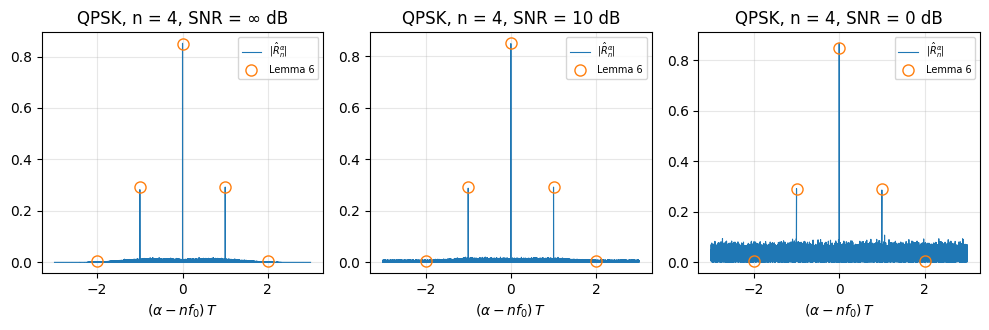

QPSK + real noise: strongest order-2 line at alpha = +0.0000, |R| = 0.708
classifier says: ('BPSK', {2: 'C', 4: 'O', 8: 'C'})


In [14]:
fig, axs = plt.subplots(1, 3)
for ax, snr in zip(axs, [None, 10, 0]):
    y, info = make_signal("QPSK", snr_db=snr, A=1.0)
    plot_caf(ax, y, 4, info, title=f"QPSK, n = 4, SNR = {'∞' if snr is None else snr} dB")
plt.tight_layout(); plt.show()

y, info = make_signal("QPSK", snr_db=5, noise="real")
alpha, R = caf(y, 2)
i = np.argmax(np.abs(R))
print(f"QPSK + real noise: strongest order-2 line at alpha = {alpha[i]:+.4f}, |R| = {np.abs(R[i]):.3f}")
print("classifier says:", classify(y))

### Lemma 6 — the CAF magnitudes

**Statement.** Writing $\alpha = nf_0+\nu$:

| Class | $M_n(nf_0+\nu)$ | support |
|---|---|---|
| BPSK | $M_2 = A^2\lvert G_2(\nu)\rvert/T$ | $\nu\in\mathbb Z/T$ |
| QPSK | $M_2\equiv0$; $\;M_4 = A^4\lvert G_4(\nu)\rvert/T$ | $\mathbb Z/T$ |
| 8PSK | $M_2\equiv M_4\equiv0$; $\;M_8 = A^8\lvert G_8(\nu)\rvert/T$ | $\mathbb Z/T$ |
| π/4-DQPSK | $M_2\equiv0$; $\;M_4 = A^4\lvert G_4(\nu)\rvert/T$ | $(\mathbb Z+\tfrac12)/T$ |
| MSK | $M_2 = A^2\lvert Q_2(\nu)\rvert/T_b$ | $(\mathbb Z+\tfrac12)/T_b$ |

**Proof.** Lemma 4 + Lemma 5, then Lemma 0 with $f = p^n$ or $q^2$; the carrier factor $e^{j2\pi nf_0t}$ shifts everything by $nf_0$.

**Check.** One toy signal per class (random $A,\varphi,t_0$, 15 dB), all relevant orders, measured vs predicted.

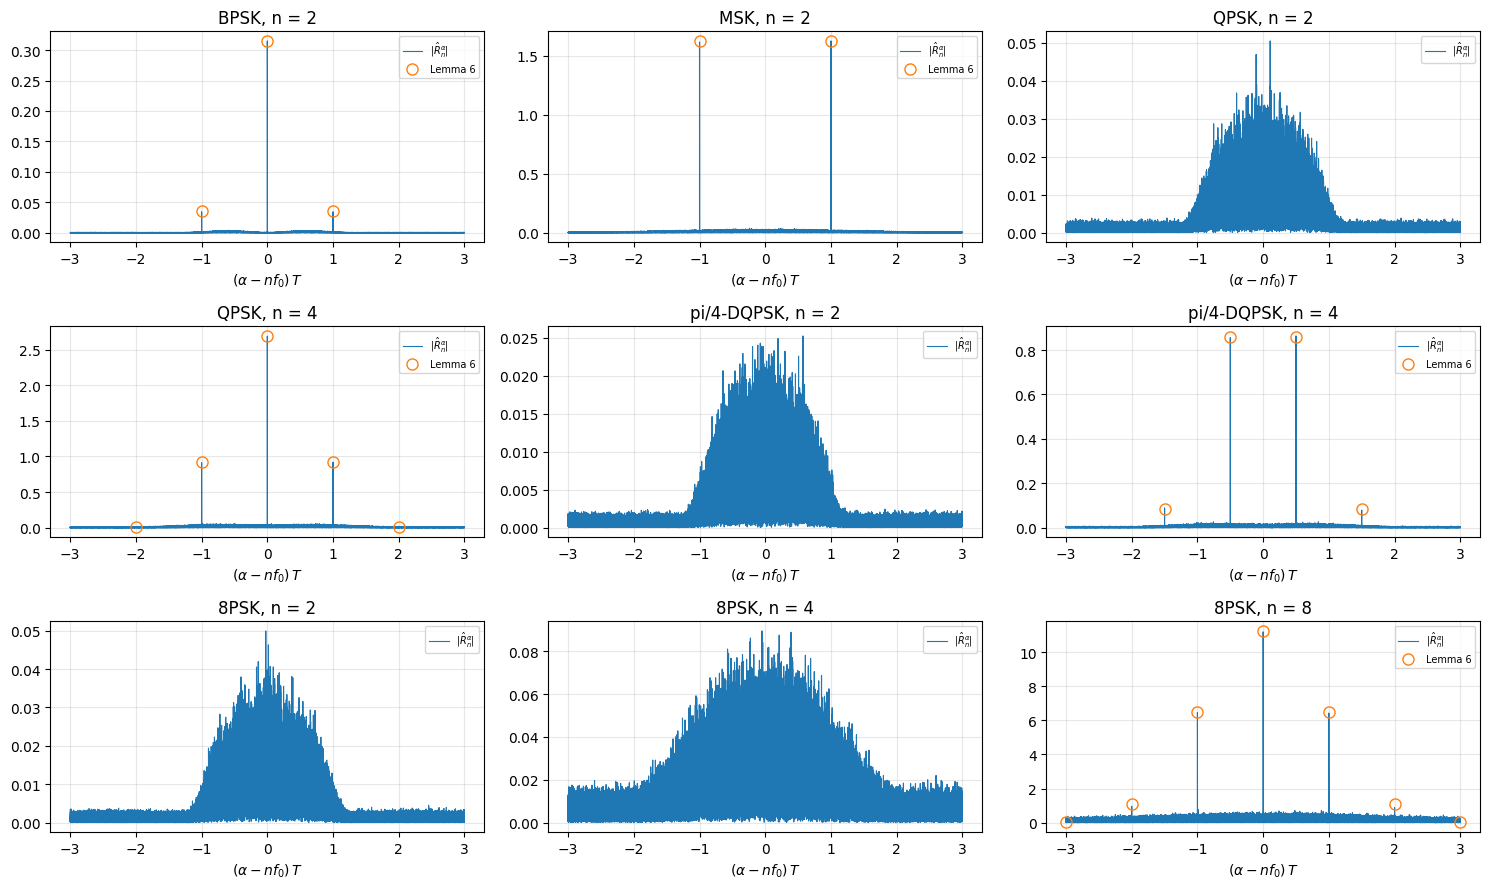

In [15]:
SIG = {cls: make_signal(cls) for cls in CLASSES}       # reused below
panels = [("BPSK", 2), ("MSK", 2), ("QPSK", 2), ("QPSK", 4),
          ("pi/4-DQPSK", 2), ("pi/4-DQPSK", 4), ("8PSK", 2), ("8PSK", 4), ("8PSK", 8)]
fig, axs = plt.subplots(3, 3, figsize=(15, 9))
for ax, (cls, n) in zip(axs.ravel(), panels):
    y, info = SIG[cls]
    plot_caf(ax, y, n, info, title=f"{cls}, n = {n}")
plt.tight_layout(); plt.show()

Notice the geometry, which is the whole theorem in pictures:

* **BPSK n=2, QPSK n=4, 8PSK n=8:** lines on the integer lattice, the tallest exactly at $\nu = 0$.
* **MSK n=2, π/4-DQPSK n=4:** lines on the half lattice, symmetric about $\nu=0$ but with **nothing at** $\nu = 0$.
* **Lower orders of the PSK group:** empty.

### Lemma 7 — symmetry and finite energy

**Statement.** Each nonzero $M_n$ is symmetric about $nf_0$, and $\sum_\alpha M_n(\alpha)^2<\infty$.

**Proof.** A real pulse has a Hermitian Fourier transform, $|\hat f(-\nu)| = |\hat f(\nu)|$, and both lattices are symmetric about 0. Square-summability is Parseval for a bounded periodic function.

In [16]:
for cls, n in [("BPSK", 2), ("MSK", 2), ("QPSK", 4), ("pi/4-DQPSK", 4), ("8PSK", 8)]:
    y, info = SIG[cls]
    alpha, R = caf(y, n)
    df = alpha[1] - alpha[0]
    c = n * info["f0"]
    rows = []
    for nu in (0.5, 1, 1.5, 2):
        step = nu / (SPS // 2 if cls == "MSK" else SPS)
        ip = int(np.argmin(np.abs(wrap(alpha - (c + step))))); im = int(np.argmin(np.abs(wrap(alpha - (c - step)))))
        rows.append(f"nu={nu:>3}/T{'b' if cls=='MSK' else ' '}: {abs(R[ip]):.3f} | {abs(R[im]):.3f}")
    print(f"{cls:10s} n={n}  M(c+nu) | M(c-nu):  " + "   ".join(rows))

BPSK       n=2  M(c+nu) | M(c-nu):  nu=0.5/T : 0.000 | 0.000   nu=  1/T : 0.035 | 0.034   nu=1.5/T : 0.000 | 0.000   nu=  2/T : 0.000 | 0.000
MSK        n=2  M(c+nu) | M(c-nu):  nu=0.5/Tb: 1.627 | 1.618   nu=  1/Tb: 0.003 | 0.005   nu=1.5/Tb: 0.002 | 0.003   nu=  2/Tb: 0.002 | 0.001
QPSK       n=4  M(c+nu) | M(c-nu):  nu=0.5/T : 0.019 | 0.013   nu=  1/T : 0.920 | 0.912   nu=1.5/T : 0.013 | 0.003   nu=  2/T : 0.021 | 0.012
pi/4-DQPSK n=4  M(c+nu) | M(c-nu):  nu=0.5/T : 0.863 | 0.856   nu=  1/T : 0.006 | 0.004   nu=1.5/T : 0.079 | 0.089   nu=  2/T : 0.003 | 0.001
8PSK       n=8  M(c+nu) | M(c-nu):  nu=0.5/T : 0.029 | 0.189   nu=  1/T : 6.432 | 6.460   nu=1.5/T : 0.106 | 0.156   nu=  2/T : 0.885 | 0.965


Where the pairs are both at noise level (e.g. integer offsets for the offset classes) there is no line; where a line exists, its mirror image has the same height.

### Lemma 8 — the symmetry center is unique

**Statement.** A nonzero, square-summable $M$ on a countable set is symmetric about **at most one** point.

**Proof.** Symmetry about two points $c_1\ne c_2$ makes $M$ invariant under translation by $2(c_2-c_1)$, so any nonzero value repeats infinitely often and $\sum M^2 = \infty$.

**Why it matters, and a discrete-time subtlety.** The proof is on the real line. In discrete time the frequency axis is a **circle** (period 1), and every reflection of a circle has two fixed points, $c$ and $c+\tfrac12$. So in discrete time centers come in antipodal pairs, and Definition 2's "the center" is ambiguous (for QPSK, $4f_0+\tfrac12$ is also a center, with $M=0$ there). The peak-symmetry test of Theorem 2 sidesteps this. The cell below counts the symmetry centers on the circle, and also shows a non-summable counterexample (an infinite comb on the real line has infinitely many centers).

In [17]:
def symmetry_centers(al, mag, df, strong=0.25, rtol=0.3):
    s = mag >= strong * mag.max()
    A_, M_ = al[s], mag[s]
    cands = set()
    for i in range(len(A_)):
        for j in range(i, len(A_)):
            for extra in (0.0, 0.5):
                cands.add(round(float(wrap((A_[i] + A_[j]) / 2 + extra)) / df))
    found = []
    for cb in sorted(cands):
        c = cb * df; ok = True
        for a, m in zip(A_, M_):
            j = int(np.argmin(np.abs(wrap(A_ - wrap(2 * c - a)))))
            if abs(wrap(A_[j] - wrap(2 * c - a))) > 1.5 * df or abs(M_[j] - m) > rtol * m:
                ok = False; break
        if ok: found.append(c)
    return found

for cls, n in [("QPSK", 4), ("pi/4-DQPSK", 4), ("MSK", 2)]:
    y, info = SIG[cls]
    alpha, R = caf(y, n)
    al, mag = detect_lines(alpha, R)
    cs = symmetry_centers(al, mag, alpha[1] - alpha[0])
    print(f"{cls:10s} n={n}: centers on the circle = {[round(float(wrap(c - n*F0)), 4) for c in cs]}  (relative to n f0)")

# infinite comb on the real line (truncated view): symmetric about every multiple of 1/2
comb = np.arange(-50, 51)
cs = [c / 2 for c in range(-6, 7) if set(np.round(2 * (c / 2) - comb, 6)) >= set(np.arange(-20, 21))]
print("Unit comb on Z (not square-summable): symmetric about", cs, "... and infinitely more")

QPSK       n=4: centers on the circle = [-0.5, 0.0]  (relative to n f0)
pi/4-DQPSK n=4: centers on the circle = [-0.5, 0.0]  (relative to n f0)
MSK        n=2: centers on the circle = [-0.5, 0.0]  (relative to n f0)
Unit comb on Z (not square-summable): symmetric about [-3.0, -2.5, -2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0] ... and infinitely more


### Lemma 9 — the value at the center

**Statement.** For the centered classes $M_n(nf_0) = A^n\big(\int p^n\big)/T > 0$, since $n$ is even and $p$ is real. For the offset classes $M_n(nf_0) = 0$, because $0$ is not on the half lattice.

In [18]:
for cls, n in [("BPSK", 2), ("QPSK", 4), ("8PSK", 8), ("pi/4-DQPSK", 4), ("MSK", 2)]:
    y, info = SIG[cls]
    alpha, R = caf(y, n)
    i = int(np.argmin(np.abs(wrap(alpha - n * info["f0"]))))
    th = info["A"]**n * np.sum(rrc()**n) / SPS if cls in ("BPSK", "QPSK", "8PSK") else 0.0
    print(f"{cls:10s} n={n}:  measured M_n(n f0) = {abs(R[i]):8.4f}    Lemma 9: {th:8.4f}")

BPSK       n=2:  measured M_n(n f0) =   0.3151    Lemma 9:   0.3149
QPSK       n=4:  measured M_n(n f0) =   2.6881    Lemma 9:   2.6920
8PSK       n=8:  measured M_n(n f0) =  11.1855    Lemma 9:  11.2413
pi/4-DQPSK n=4:  measured M_n(n f0) =   0.0032    Lemma 9:   0.0000
MSK        n=2:  measured M_n(n f0) =   0.0033    Lemma 9:   0.0000


## 5. Theorems

### Theorem 1 — the class-to-type map is injective

| Class | $\tau_2$ | $\tau_4$ | $\tau_8$ |
|---|---|---|---|
| BPSK | C | – | – |
| MSK | O | – | – |
| QPSK | ∅ | C | – |
| π/4-DQPSK | ∅ | O | – |
| 8PSK | ∅ | ∅ | C |
| noise only | ∅ | ∅ | ∅ |

**Proof.** Lemma 6 says which $M_n$ vanish; Lemmas 7–8 give the unique center $nf_0$; Lemma 9 decides C versus O. The rows are distinct, and no row depends on $A, f_0, \varphi, t_0, T$ or the noise.

**Check.** First the toy signals, then random parameters (including a random carrier offset), then a different pulse (rectangular instead of RRC).

In [19]:
print(f"{'class':12s} tau_2 tau_4 tau_8   decision")
for cls in CLASSES + ["noise"]:
    y = SIG[cls][0] if cls in SIG else make_signal("noise")[0]
    c, t = classify(y)
    print(f"{cls:12s} {t[2]:>5s} {t[4]:>5s} {t[8]:>5s}   {c}")

class        tau_2 tau_4 tau_8   decision
BPSK             C     C     C   BPSK
QPSK             ∅     C     C   QPSK
8PSK             ∅     ∅     C   8PSK
pi/4-DQPSK       ∅     O     O   pi/4-DQPSK
MSK              O     O     C   MSK
noise            ∅     ∅     ∅   noise


In [20]:
def confusion(trials=6, **kw):
    labels = CLASSES + ["noise"]
    C = np.zeros((len(labels), len(labels)), int)
    for i, cls in enumerate(labels):
        for _ in range(trials):
            f0 = int(rng.integers(-20, 21)) / 1024          # random carrier offset (on grid)
            y, _ = make_signal(cls, f0=f0, **kw)
            C[i, labels.index(classify(y)[0])] += 1
    print(f"{'true / decided':>14s}" + "".join(f"{l[:6]:>8s}" for l in labels))
    for i, l in enumerate(labels):
        print(f"{l:>14s}" + "".join(f"{v:8d}" for v in C[i]))

print("RRC pulse, random A, phi, t0, f0:"); confusion()
print("\nRectangular pulse (same theorem, different pulse):"); confusion(pulse=rect())

RRC pulse, random A, phi, t0, f0:
true / decided    BPSK    QPSK    8PSK  pi/4-D     MSK   noise
          BPSK       6       0       0       0       0       0
          QPSK       0       6       0       0       0       0
          8PSK       0       0       6       0       0       0
    pi/4-DQPSK       0       0       0       6       0       0
           MSK       0       0       0       0       6       0
         noise       0       0       0       0       0       6

Rectangular pulse (same theorem, different pulse):
true / decided    BPSK    QPSK    8PSK  pi/4-D     MSK   noise
          BPSK       6       0       0       0       0       0
          QPSK       0       6       0       0       0       0
          8PSK       0       0       6       0       0       0
    pi/4-DQPSK       0       0       0       6       0       0
           MSK       0       0       0       0       6       0
         noise       0       0       0       0       0       6


### Theorem 2 — the peak-symmetry test

**Statement.** In a centered class the strongest line is **unique and sits at the center** (strict dominance); in an offset class $M_n$ is **not** symmetric about its strongest line.

**Proof.** For even $n$, $p^n\ge0$, so $|G_n(\nu)| = \big|\int p^n e^{-j2\pi\nu t}\big| < \int p^n = G_n(0)$ for $\nu\ne0$ (equality would need a phase that is constant on a set of positive measure). In an offset class the peak is not at the center (the center value is 0), and by Lemma 8 $M_n$ cannot be symmetric about a second point.

**Check.** Reflect the measured lines about the strongest one. For BPSK the reflection lands on the lines; for MSK it lands in empty space.

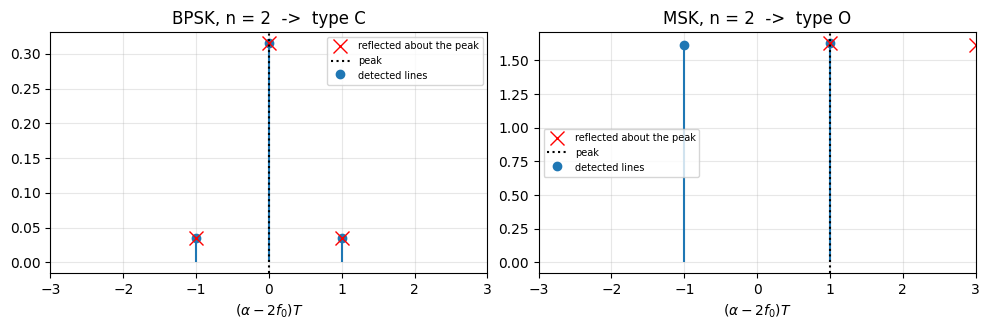

In [21]:
fig, axs = plt.subplots(1, 2)
for ax, cls in zip(axs, ["BPSK", "MSK"]):
    y, info = SIG[cls]
    alpha, R = caf(y, 2)
    al, mag = detect_lines(alpha, R)
    i = int(np.argmax(mag)); a_star = al[i]
    x  = wrap(al - 2 * info["f0"]) * SPS
    xm = wrap(2 * a_star - al - 2 * info["f0"]) * SPS
    ax.stem(x, mag, basefmt=" ", label="detected lines")
    ax.plot(xm, mag, "rx", ms=10, label="reflected about the peak")
    ax.axvline(wrap(a_star - 2 * info["f0"]) * SPS, color="k", ls=":", label="peak")
    t = line_type(al, mag, alpha[1] - alpha[0])[0]
    ax.set_title(f"{cls}, n = 2  ->  type {t}"); ax.set_xlim(-3, 3); ax.legend(fontsize=7)
    ax.set_xlabel(r"$(\alpha - 2f_0)T$")
plt.tight_layout(); plt.show()

### Theorem 3 — consistency

**Statement.** $E|\hat R_n^\alpha(N) - R_n^\alpha|^2 = O(1/N)$, so threshold decisions — and the classification — become error-free as $N\to\infty$ (under a standard mixing condition, A7).

**Check 1.** Mean-square error of $\hat R$ at the center line for BPSK ($n=2$) and QPSK ($n=4$), with the true value known in closed form. The slope on a log-log plot should be −1.

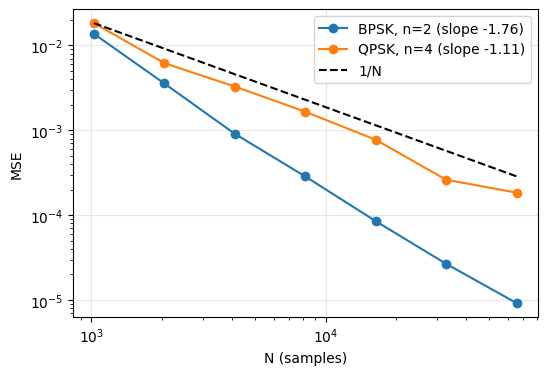

In [22]:
Ns = [2**k for k in range(10, 17)]
fig, ax = plt.subplots(figsize=(6, 4))
for cls, n, Ean in [("BPSK", 2, 1.0), ("QPSK", 4, -1.0)]:
    truth = Ean * np.sum(rrc()**n) / SPS
    mse = []
    for N in Ns:
        e = []
        for _ in range(40):
            y, _ = make_signal(cls, nsamp=N, A=1.0, phi=0.0, t0=0, snr_db=10)
            k = np.arange(N)
            e.append(abs(np.mean(y**n * np.exp(-2j * np.pi * n * F0 * k)) - truth)**2)
        mse.append(np.mean(e))
    slope = np.polyfit(np.log(Ns), np.log(mse), 1)[0]
    ax.loglog(Ns, mse, "o-", label=f"{cls}, n={n} (slope {slope:.2f})")
ax.loglog(Ns, [mse[0] * Ns[0] / N for N in Ns], "k--", label="1/N")
ax.set_xlabel("N (samples)"); ax.set_ylabel("MSE"); ax.legend(); plt.show()

**Check 2.** Probability of correct classification versus $N$ at 10 dB. The high-order class (8PSK) needs the most data: its statistic $y^8$ is by far the noisiest.

In [23]:
sizes = [2**12, 2**14, 2**16, 2**18]
trials = 8
print(f"{'N':>8s}" + "".join(f"{c[:6]:>9s}" for c in CLASSES))
for N in sizes:
    row = []
    for cls in CLASSES:
        ok = sum(classify(make_signal(cls, nsamp=N, snr_db=10)[0])[0] == cls for _ in range(trials))
        row.append(ok / trials)
    print(f"{N:8d}" + "".join(f"{v:9.2f}" for v in row))

       N     BPSK     QPSK     8PSK   pi/4-D      MSK
    4096     1.00     0.00     0.00     0.00     1.00
   16384     1.00     0.62     0.88     0.50     1.00
   65536     1.00     1.00     0.88     1.00     1.00
  262144     1.00     1.00     1.00     1.00     1.00


## 6. Plain DQPSK is excluded

**Proposition.** With increments uniform on $\{0,\pi/2,\pi,3\pi/2\}$, the DQPSK symbol sequence has **the same joint law** as i.i.d. QPSK, so no statistic can tell them apart.

**Proof.** Each increment is uniform on the group of quarter turns and independent of the past; adding it to any phase gives a uniform phase independent of the past.

**Check.** The transition matrices (probability of moving from constellation point $i$ to $j$) are identical and uniform for QPSK and DQPSK, while π/4-DQPSK jumps between two disjoint constellations. The CAFs of DQPSK and QPSK overlay, and the classifier calls DQPSK "QPSK".

QPSK  (states = 4 points):
 [[0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.26]
 [0.25 0.25 0.25 0.25]]
DQPSK (states = 4 points):
 [[0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]]
pi/4-DQPSK (states = 8 points; even rows only reach odd columns):
 [[0.   0.25 0.   0.25 0.   0.25 0.   0.25]
 [0.25 0.   0.25 0.   0.25 0.   0.25 0.  ]
 [0.   0.25 0.   0.25 0.   0.25 0.   0.25]
 [0.25 0.   0.25 0.   0.24 0.   0.25 0.  ]
 [0.   0.25 0.   0.25 0.   0.25 0.   0.25]
 [0.25 0.   0.25 0.   0.25 0.   0.25 0.  ]
 [0.   0.25 0.   0.25 0.   0.25 0.   0.25]
 [0.25 0.   0.26 0.   0.25 0.   0.25 0.  ]]


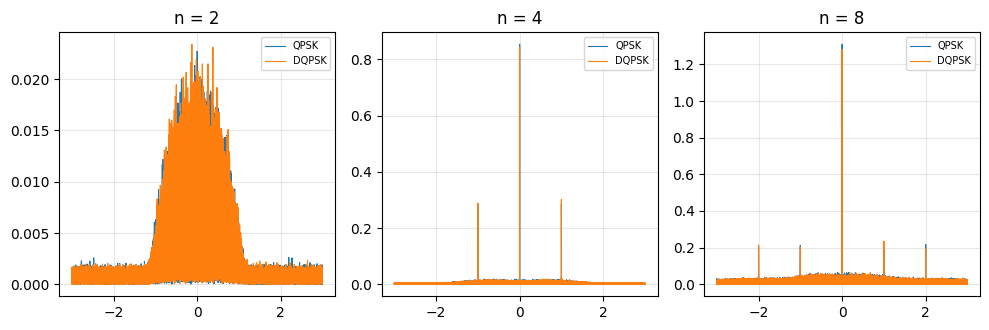

classifier on DQPSK: ('QPSK', {2: '∅', 4: 'C', 8: 'C'})


In [24]:
def transitions(a, npts, offset):
    idx = np.round((np.angle(a) - offset) / (2 * np.pi / npts)).astype(int) % npts
    Tm = np.zeros((npts, npts))
    np.add.at(Tm, (idx[:-1], idx[1:]), 1)
    return Tm / Tm.sum(axis=1, keepdims=True)

np.set_printoptions(precision=2, suppress=True)
print("QPSK  (states = 4 points):\n", transitions(psk_symbols(4, 200_000), 4, np.pi / 4))
print("DQPSK (states = 4 points):\n", transitions(dqpsk_symbols(200_000), 4, 0.0))
print("pi/4-DQPSK (states = 8 points; even rows only reach odd columns):\n",
      transitions(pi4_dqpsk_symbols(200_000), 8, 0.0))

y_d, info_d = make_signal("DQPSK", A=1.0, phi=0.3, t0=3)
y_q, info_q = make_signal("QPSK",  A=1.0, phi=0.3, t0=3)
fig, axs = plt.subplots(1, 3)
for ax, n in zip(axs, (2, 4, 8)):
    for y, lab in [(y_q, "QPSK"), (y_d, "DQPSK")]:
        alpha, R = caf(y, n); x = wrap(alpha - n * F0) * SPS; s = np.abs(x) < 3
        ax.plot(x[s], np.abs(R[s]), lw=0.8, label=lab)
    ax.set_title(f"n = {n}"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("classifier on DQPSK:", classify(y_d))

## 7. Remarks: when the assumptions fail

### A dispersive channel breaks the blind test (A1/A3)

Through a channel $h$ the effective pulse $g = p * h$ is complex, so $M_n$ need not be symmetric and the center value $\int g^n$ can cancel. With $h = \delta[t] + j\,\delta[t - 3T]$, $g^2 \approx p^2(t) - p^2(t-3T) + 2j\,p(t)p(t-3T)$: the main terms cancel on every line, and what survives (from the RRC tails) is small and no longer symmetric. The peak-symmetry test then reports "offset" and BPSK is misclassified (here as MSK). A flat complex gain, by contrast, is harmless (it is just $A e^{j\varphi}$), and mild multipath survives in this example.

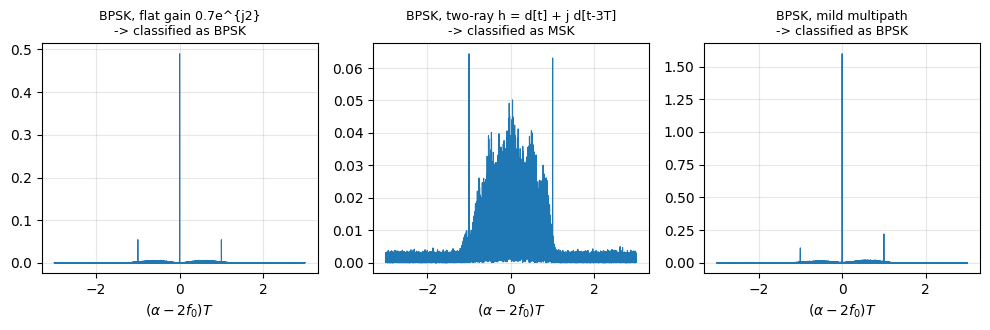

In [25]:
h = np.zeros(3 * SPS + 1, complex); h[0] = 1; h[-1] = 1j
cases = [("flat gain 0.7e^{j2}", np.array([0.7 * np.exp(2j)])),
         ("two-ray h = d[t] + j d[t-3T]", h),
         ("mild multipath", np.array([1, 0, 0, 0.5j, 0, 0.2]))]
fig, axs = plt.subplots(1, 3)
for ax, (name, ch) in zip(axs, cases):
    y, info = make_signal("BPSK", channel=ch, A=1.0)
    alpha, R = caf(y, 2); x = wrap(alpha - 2 * F0) * SPS; s = np.abs(x) < 3
    ax.plot(x[s], np.abs(R[s]), lw=0.8)
    ax.set_title(f"BPSK, {name}\n-> classified as {classify(y)[0]}", fontsize=9)
    ax.set_xlabel(r"$(\alpha - 2f_0)T$")
plt.tight_layout(); plt.show()

The two-ray case also illustrates the fix mentioned in the write-up: the lines have not moved off the integer lattice; they have cancelled (and lost their symmetry) only because the zero-lag CAF integrates over frequency. Estimating $f_0$ and $T$ and using nonzero lags or the full spectral correlation function (which does not integrate over frequency) restores separability.

### Other points

* **Discrete time.** On the sampled frequency circle, symmetry centers come in pairs $c, c+\tfrac12$ (Lemma 8). The peak-symmetry test is unaffected as long as the offset lattices do not contain $\tfrac12$, which requires $T$ (and $T_b$) to be an **even** number of samples. The toy example uses $T=16$, $T_b=8$. When the sampling rate is an integer multiple of $1/T$, the line lattices are also closed under aliasing, so aliased lines land on lattice points and the symmetry survives.
* **Time-varying fading, phase noise, clock drift** (A1) smear the lines, and the eighth order suffers most.
* **Unscrambled data, preambles** (A2) add extra lines.
* **Co-channel signals** (A6) need cyclic cumulants rather than moments.

## Summary

| Step | What it says | Seen in |
|---|---|---|
| Lemmas 1–3 | which symbol moments survive | tables of $E[a^r]$ and index patterns |
| Lemma 4 | mean of $s^n$ is a periodic or **alternating** pulse train | ensemble averages |
| Lemma 0 + 6 | periodic ⇒ integer lattice; alternating ⇒ half lattice | CAF grid |
| Lemmas 7–9 | symmetric about $nf_0$; positive or zero center | mirror tables, center values |
| Theorem 1 | $(\tau_2,\tau_4,\tau_8)$ identifies the class | confusion matrices |
| Theorem 2 | "is the pattern symmetric about the peak?" | reflection plot |
| Theorem 3 | MSE $\propto 1/N$ | log-log plot, $P_c$ vs $N$ |